# Colombo Weather: Ensemble Learning for Next-Day Temperature Prediction

**Module:** Machine Learning and Pattern Recognition, Hands-on Project

**Objective:** Predict tomorrow's maximum temperature in Colombo, Sri Lanka, and compare Bagging, Boosting, Stacking and a Hybrid ARIMA + Random Forest model.

**Dataset:** Daily weather for Colombo (2015 to 2025) from the Open-Meteo Historical Weather API.

**Contents**
1. Setup
2. Data collection
3. Exploratory analysis
4. Feature engineering
5. Train/test split
6. Bagging
7. Boosting
8. Voting and Stacking
9. Hybrid ARIMA + RF
10. Model comparison and cross-validation
11. Interpretation
12. Saving files for the dashboard

In [33]:
!pip install xgboost lightgbm catboost statsmodels streamlit

In [34]:
import requests, pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 6.9271, "longitude": 79.8612,   # Colombo
    "start_date": "2015-01-01", "end_date": "2025-10-31",
    "daily": "temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max",
    "timezone": "Asia/Colombo",
}
data = requests.get(url, params=params).json()
df = pd.DataFrame(data["daily"])
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time")
df.to_csv("colombo_weather.csv")   # save it so you never re-download
print(df.shape); df.head()

(3957, 4)


,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
time,,,,
2015-01-01,28.4,23.2,1.4,11.4
2015-01-02,28.8,22.9,0.0,9.6
2015-01-03,29.9,20.9,0.0,9.9
2015-01-04,29.8,23.2,0.0,8.8
2015-01-05,29.6,23.0,0.4,7.9


In [35]:
df.isna().sum()

,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
wind_speed_10m_max,0


In [36]:
df = df.interpolate()

In [37]:
df.isna().sum()

,0
temperature_2m_max,0
temperature_2m_min,0
precipitation_sum,0
wind_speed_10m_max,0


In [38]:
import numpy as np
df = df.rename(columns={"temperature_2m_max":"tmax","temperature_2m_min":"tmin",
                        "precipitation_sum":"rain","wind_speed_10m_max":"wind"})

df["target"] = df["tmax"].shift(-1)          # tomorrow's tmax
for l in [1, 2, 3, 7]:
    df[f"tmax_lag{l}"] = df["tmax"].shift(l)
df["tmax_roll7"] = df["tmax"].rolling(7).mean()
df["rain_roll7"] = df["rain"].rolling(7).sum()
df["month"] = df.index.month
df["doy_sin"] = np.sin(2*np.pi*df.index.dayofyear/365)
df["doy_cos"] = np.cos(2*np.pi*df.index.dayofyear/365)
df = df.dropna()

In [39]:
X = df.drop(columns="target"); y = df["target"]
split = int(len(df)*0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

In [40]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

results = []
preds = {}   # keep predictions for plots later

def evaluate(name, model, kind):
    t = time.time()
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    results.append({
        "Model": name,
        "Type": kind,
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE": mean_absolute_error(y_test, p),
        "R2": r2_score(y_test, p),
        "Train time (s)": round(time.time() - t, 2),
    })
    print(f"{name}: RMSE={results[-1]['RMSE']:.3f}  MAE={results[-1]['MAE']:.3f}  R2={results[-1]['R2']:.3f}")

In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

# Baselines
class Persistence:            # predicts tomorrow = today
    def fit(self, X, y): return self
    def predict(self, X): return X["tmax"].values

evaluate("Persistence (tomorrow = today)", Persistence(), "Baseline")
evaluate("Linear Regression", LinearRegression(), "Baseline")

# Single tree vs bagging (shows why bagging helps)
evaluate("Decision Tree", DecisionTreeRegressor(random_state=42), "Single model")
evaluate("Bagging (trees)", BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, random_state=42, n_jobs=-1), "Bagging")
evaluate("Random Forest", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), "Bagging")

Persistence (tomorrow = today): RMSE=1.103  MAE=0.798  R2=0.550
Linear Regression: RMSE=0.978  MAE=0.732  R2=0.646
Decision Tree: RMSE=1.295  MAE=0.968  R2=0.380
Bagging (trees): RMSE=0.966  MAE=0.729  R2=0.655
Random Forest: RMSE=0.965  MAE=0.730  R2=0.655


In [42]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor

evaluate("Gradient Boosting", GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, random_state=42), "Boosting")
evaluate("XGBoost", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42), "Boosting")
evaluate("LightGBM", LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1), "Boosting")
evaluate("CatBoost", CatBoostRegressor(iterations=300, learning_rate=0.05, verbose=0, random_seed=42), "Boosting")

Gradient Boosting: RMSE=0.969  MAE=0.726  R2=0.653
XGBoost: RMSE=0.970  MAE=0.723  R2=0.652
LightGBM: RMSE=0.965  MAE=0.725  R2=0.655
CatBoost: RMSE=0.950  MAE=0.720  R2=0.666


In [43]:
res = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
res

,Model,Type,RMSE,MAE,R2,Train time (s)
0,CatBoost,Boosting,0.949849,0.720254,0.666432,0.90
1,LightGBM,Boosting,0.965317,0.725044,0.655480,0.36
2,Random Forest,Bagging,0.965345,0.729996,0.655459,17.59
3,Bagging (trees),Bagging,0.966256,0.728891,0.654809,20.18
4,Gradient Boosting,Boosting,0.969010,0.725526,0.652838,3.42
5,XGBoost,Boosting,0.969877,0.723343,0.652217,0.44
6,Linear Regression,Baseline,0.978390,0.732099,0.646085,0.02
7,Persistence (tomorrow = today),Baseline,1.102776,0.798101,0.550376,0.01
8,Decision Tree,Single model,1.294741,0.968354,0.380215,0.09


In [44]:
from sklearn.ensemble import VotingRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV

base = [
    ("rf", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
    ("lgbm", LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1)),
    ("cat", CatBoostRegressor(iterations=300, learning_rate=0.05, verbose=0, random_seed=42)),
]

evaluate("Voting (avg of RF+LGBM+Cat)", VotingRegressor(base), "Voting")
evaluate("Stacking (Ridge meta)", StackingRegressor(estimators=base, final_estimator=RidgeCV(), cv=5), "Stacking")

Voting (avg of RF+LGBM+Cat): RMSE=0.949  MAE=0.716  R2=0.667
Stacking (Ridge meta): RMSE=0.947  MAE=0.718  R2=0.668


In [45]:
from statsmodels.tsa.arima.model import ARIMA

y_all = pd.concat([y_train, y_test]).asfreq("D")

# 1) Fit ARIMA on TRAIN only
arima_res = ARIMA(y_train.asfreq("D"), order=(2, 0, 1)).fit()

# 2) One-step-ahead ARIMA predictions for train AND test (params stay fixed)
arima_all = arima_res.apply(y_all).fittedvalues
arima_train = arima_all.loc[y_train.index].values
arima_test = arima_all.loc[y_test.index].values

# 3) RF learns the residuals (what ARIMA got wrong)
resid_train = y_train.values - arima_train
rf_resid = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf_resid.fit(X_train, resid_train)

# 4) Final = ARIMA + RF correction
p = arima_test + rf_resid.predict(X_test)

# score it
preds["Hybrid ARIMA+RF"] = p
results.append({
    "Model": "Hybrid ARIMA+RF", "Type": "Hybrid",
    "RMSE": np.sqrt(mean_squared_error(y_test, p)),
    "MAE": mean_absolute_error(y_test, p),
    "R2": r2_score(y_test, p),
    "Train time (s)": np.nan,
})

# also score ARIMA alone, to show the hybrid adds something
pa = arima_test
preds["ARIMA only"] = pa
results.append({"Model": "ARIMA only", "Type": "Baseline",
    "RMSE": np.sqrt(mean_squared_error(y_test, pa)),
    "MAE": mean_absolute_error(y_test, pa),
    "R2": r2_score(y_test, pa), "Train time (s)": np.nan})

,Model,Type,RMSE,MAE,R2,Train time (s)
0,Stacking (Ridge meta),Stacking,0.947300,0.718201,0.668220,56.88
1,Voting (avg of RF+LGBM+Cat),Voting,0.948914,0.715733,0.667088,10.77
2,Hybrid ARIMA+RF,Hybrid,0.949488,0.708357,0.666685,NaN
3,CatBoost,Boosting,0.949849,0.720254,0.666432,0.90
4,LightGBM,Boosting,0.965317,0.725044,0.655480,0.36
5,Random Forest,Bagging,0.965345,0.729996,0.655459,17.59
6,Bagging (trees),Bagging,0.966256,0.728891,0.654809,20.18
7,Gradient Boosting,Boosting,0.969010,0.725526,0.652838,3.42
8,XGBoost,Boosting,0.969877,0.723343,0.652217,0.44
9,Linear Regression,Baseline,0.978390,0.732099,0.646085,0.02


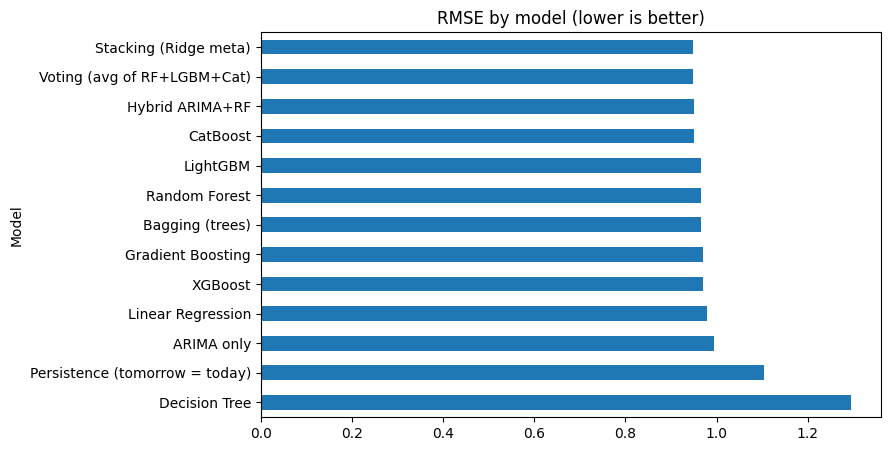

In [46]:
res = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(res)

import matplotlib.pyplot as plt
res.plot.barh(x="Model", y="RMSE", figsize=(8,5), legend=False, title="RMSE by model (lower is better)")
plt.gca().invert_yaxis(); plt.show()

In [47]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)
cv_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "LightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=300, learning_rate=0.05, verbose=0, random_seed=42),
}
cv_rows = []
for name, m in cv_models.items():
    s = -cross_val_score(m, X, y, cv=tscv, scoring="neg_root_mean_squared_error")
    cv_rows.append({"Model": name, "CV RMSE mean": s.mean(), "CV RMSE std": s.std()})
cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE mean")
cv_table

,Model,CV RMSE mean,CV RMSE std
3,CatBoost,0.850868,0.063571
0,Linear Regression,0.857146,0.075401
1,Random Forest,0.862914,0.064699
2,LightGBM,0.897764,0.056477


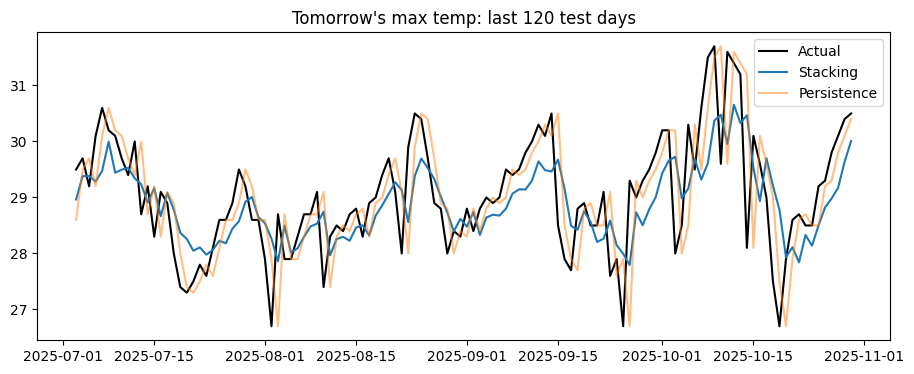

In [48]:
last = 120
plt.figure(figsize=(11,4))
plt.plot(y_test.index[-last:], y_test.values[-last:], label="Actual", color="black")
plt.plot(y_test.index[-last:], preds["Stacking (Ridge meta)"][-last:], label="Stacking")
plt.plot(y_test.index[-last:], preds["Persistence (tomorrow = today)"][-last:], label="Persistence", alpha=0.5)
plt.legend(); plt.title("Tomorrow's max temp: last 120 test days"); plt.show()

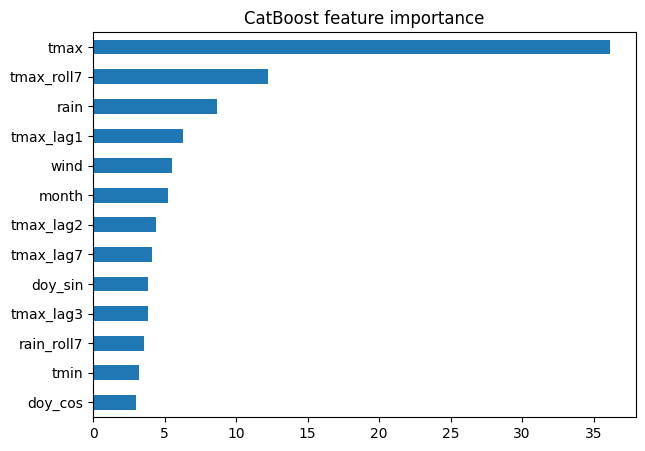

In [49]:
cat = CatBoostRegressor(iterations=300, learning_rate=0.05, verbose=0, random_seed=42).fit(X_train, y_train)
imp = pd.Series(cat.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(figsize=(7,5), title="CatBoost feature importance"); plt.show()

In [50]:
import joblib
final = CatBoostRegressor(iterations=300, learning_rate=0.05, verbose=0, random_seed=42).fit(X, y)  # trained on all data
joblib.dump(final, "best_model.joblib")
df.to_csv("features.csv")
res.to_csv("results.csv", index=False)
pd.DataFrame(preds, index=y_test.index).assign(Actual=y_test).to_csv("predictions.csv")
imp.to_csv("importance.csv")

In [51]:
cv_table.to_csv("cv_results.csv", index=False)

In [52]:
import os
need = ["best_model.joblib","features.csv","results.csv","predictions.csv","importance.csv","cv_results.csv"]
print({f: os.path.exists(f) for f in need})

{'best_model.joblib': True, 'features.csv': True, 'results.csv': True, 'predictions.csv': True, 'importance.csv': True, 'cv_results.csv': True}


In [53]:
%%writefile app.py
import streamlit as st, pandas as pd, numpy as np, joblib

st.set_page_config(page_title="Colombo Weather Ensemble Dashboard", layout="wide")

@st.cache_data
def load():
    feats = pd.read_csv("features.csv", index_col=0, parse_dates=True)
    res = pd.read_csv("results.csv")
    preds = pd.read_csv("predictions.csv", index_col=0, parse_dates=True)
    imp = pd.read_csv("importance.csv", index_col=0).iloc[:, 0]
    cv = pd.read_csv("cv_results.csv")
    return feats, res, preds, imp, cv

feats, res, preds, imp, cv = load()
model = joblib.load("best_model.joblib")
cols = [c for c in feats.columns if c != "target"]

st.title("🌦️ Colombo Weather: Ensemble Learning Dashboard")
st.caption("Predicting tomorrow's max temperature using Bagging, Boosting, Stacking and a Hybrid ARIMA+RF model. Data: Open-Meteo.")

page = st.sidebar.radio("Page", ["Data overview", "Model comparison", "Feature importance", "Predict tomorrow"])

if page == "Data overview":
    st.subheader("Daily max temperature (°C)")
    st.line_chart(feats["tmax"])
    c1, c2 = st.columns(2)
    c1.subheader("Average max temp by month")
    c1.bar_chart(feats.groupby("month")["tmax"].mean())
    c2.subheader("Average rainfall by month (mm)")
    c2.bar_chart(feats.groupby("month")["rain"].mean())
    st.write(f"{len(feats):,} days, {feats.index.min().date()} to {feats.index.max().date()}")
    st.dataframe(feats.tail(10))

elif page == "Model comparison":
    st.subheader("Hold-out test results (lower RMSE is better)")
    st.dataframe(res.style.format({"RMSE": "{:.3f}", "MAE": "{:.3f}", "R2": "{:.3f}"}), use_container_width=True)
    st.bar_chart(res.set_index("Model")["RMSE"])
    st.subheader("Time-series cross-validation")
    st.dataframe(cv, use_container_width=True)
    st.info("Top models are within noise of each other under CV: ensembles give modest gains on this smooth, seasonal target.")
    st.subheader("Actual vs predicted (last 120 test days)")
    choice = st.multiselect("Models", [c for c in preds.columns if c != "Actual"],
                            default=["Stacking (Ridge meta)", "Hybrid ARIMA+RF"])
    st.line_chart(preds[["Actual"] + choice].tail(120))

elif page == "Feature importance":
    st.subheader("CatBoost feature importance")
    st.bar_chart(imp.sort_values(ascending=False))

else:
    st.subheader("Predict tomorrow's max temperature")
    last = feats.iloc[-1]
    st.caption("Defaults are the most recent day in the dataset. Change them to try your own scenario.")
    c1, c2, c3 = st.columns(3)
    date = c1.date_input("Today's date", feats.index[-1].date())
    tmax = c1.number_input("Today's max temp (°C)", value=float(last["tmax"]))
    tmin = c1.number_input("Today's min temp (°C)", value=float(last["tmin"]))
    rain = c2.number_input("Today's rain (mm)", value=float(last["rain"]))
    wind = c2.number_input("Today's max wind (km/h)", value=float(last["wind"]))
    rain7 = c2.number_input("Rain total, last 7 days (mm)", value=float(last["rain_roll7"]))
    l1 = c3.number_input("Max temp 1 day ago", value=float(last["tmax_lag1"]))
    l2 = c3.number_input("Max temp 2 days ago", value=float(last["tmax_lag2"]))
    l3 = c3.number_input("Max temp 3 days ago", value=float(last["tmax_lag3"]))
    l7 = c3.number_input("Max temp 7 days ago", value=float(last["tmax_lag7"]))
    roll7 = st.number_input("Average max temp, last 7 days", value=float(last["tmax_roll7"]))

    d = pd.Timestamp(date)
    row = {"tmax": tmax, "tmin": tmin, "rain": rain, "wind": wind,
           "tmax_lag1": l1, "tmax_lag2": l2, "tmax_lag3": l3, "tmax_lag7": l7,
           "tmax_roll7": roll7, "rain_roll7": rain7, "month": d.month,
           "doy_sin": np.sin(2*np.pi*d.dayofyear/365), "doy_cos": np.cos(2*np.pi*d.dayofyear/365)}
    if st.button("Predict"):
        p = model.predict(pd.DataFrame([row])[cols])[0]
        st.metric("Predicted max temp tomorrow", f"{p:.1f} °C")
        st.caption("Typical error is about ±1 °C (test RMSE ≈ 0.95).")

Overwriting app.py


In [54]:
%%writefile requirements.txt
streamlit
pandas
numpy
joblib
catboost

Overwriting requirements.txt


In [55]:
import shutil, os
from google.colab import files

os.makedirs("ensemble-dashboard", exist_ok=True)
for f in ["app.py","requirements.txt","best_model.joblib","features.csv",
          "results.csv","predictions.csv","importance.csv","cv_results.csv"]:
    shutil.copy(f, "ensemble-dashboard/")

shutil.make_archive("ensemble-dashboard", "zip", "ensemble-dashboard")
files.download("ensemble-dashboard.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
import altair as alt
import pandas as pd

# Load the features dataset that contains 'tmax'
feats = pd.read_csv("features.csv", index_col=0, parse_dates=True)

d = feats[["tmax"]].reset_index()
d.columns = ["date", "tmax"]

# Note: st.altair_chart is intended for Streamlit apps.
# To view it in Colab, we can display the chart directly.
chart = alt.Chart(d).mark_line().encode(
    x=alt.X("date:T", title="Date"),
    y=alt.Y("tmax:Q", scale=alt.Scale(domain=[24, 37]), title="Max temp (°C)"),
).properties(
    width=800,
    height=400
)
chart

alt.Chart(...)

In [57]:
import catboost; print("CatBoost version:", catboost.__version__)

from google.colab import files
files.download("app.py")
files.download("requirements.txt")

CatBoost version: 1.2.10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
from google.colab import files
files.download("colombo_weather.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>